Unsupervised Leaning:  
Clustring

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = sns.load_dataset('iris')

In [3]:
df.shape

(150, 5)

In [4]:
df.isnull().sum().sum()

np.int64(0)

In [5]:
df.head(3)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa


In [6]:
X=df.drop(columns=['species'])

In [7]:
X.head(2)

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2


In [8]:
from sklearn.cluster import KMeans

In [9]:
kmeans = KMeans(n_clusters=3,random_state=11)

In [10]:
X['cluster']=kmeans.fit_predict(X)

In [11]:
X.head(3)

,sepal_length,sepal_width,petal_length,petal_width,cluster
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0


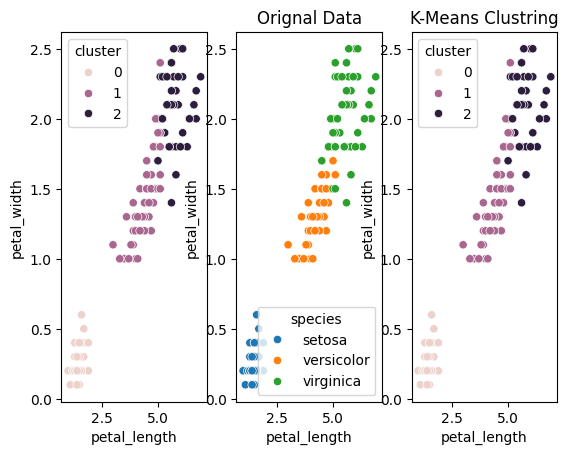

In [15]:
plt.Figure(figsize=(12,3))
plt.subplot(1,3,1)
sns.scatterplot(x='petal_length',y='petal_width',hue='cluster',data=X)
plt.subplot(1,3,2)
plt.title("Orignal Data")
sns.scatterplot(x='petal_length',y='petal_width',hue='species',data=df)
plt.subplot(1,3,3)
plt.title("K-Means Clustring")
sns.scatterplot(x='petal_length',y='petal_width',hue='cluster',data=X)
plt.show()

In [17]:
# K-Means is Simple,Fast,Works well with Large Dataset

DBSCAN:  
DBSCAN(Density-Based Spatial Clustring of Application with Noise)
Unlike K-Means,DBSCAN does not require you to specify the number of cluster

In [18]:
from sklearn.cluster import DBSCAN

In [31]:
dbscan= DBSCAN(eps=0.5,min_samples=10)

In [32]:
X['db_cluster'] = dbscan.fit_predict(X.drop(columns = ['cluster']))

In [33]:
X.head(4)

,sepal_length,sepal_width,petal_length,petal_width,cluster,db_cluster
0,5.1,3.5,1.4,0.2,0,0
1,4.9,3.0,1.4,0.2,0,0
2,4.7,3.2,1.3,0.2,0,0
3,4.6,3.1,1.5,0.2,0,0


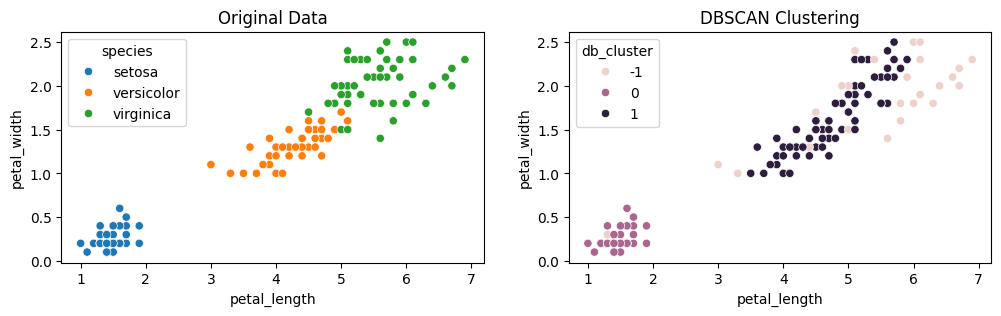

In [34]:
plt.figure(figsize=(12,3))
plt.subplot(1,2,1)
plt.title("Original Data")
sns.scatterplot(x='petal_length' , y='petal_width' , hue='species' , data=df)
plt.subplot(1,2,2)
plt.title("DBSCAN Clustering")
sns.scatterplot(x='petal_length' , y='petal_width' , hue='db_cluster' , data=X)
plt.show()


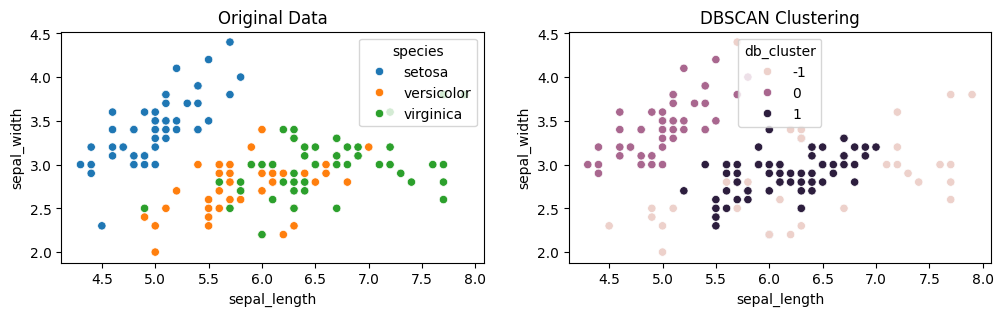

In [35]:
plt.figure(figsize=(12,3))
plt.subplot(1,2,1)
plt.title("Original Data")
sns.scatterplot(x='sepal_length' , y='sepal_width' , hue='species' , data=df)
plt.subplot(1,2,2)
plt.title("DBSCAN Clustering")
sns.scatterplot(x='sepal_length' , y='sepal_width' , hue='db_cluster' , data=X)
plt.show()


Hierarchical Clustering:  
Hierarchicalo clustring creates a tree-loke structure of clusters

In [36]:
from sklearn.cluster import AgglomerativeClustering

In [37]:
!pip install scipy

In [38]:
from scipy.cluster.hierarchy import dendrogram ,linkage

In [39]:
#Create a Dendrogram
linked = linkage(X.drop(columns=['cluster','db_cluster']),method='ward')

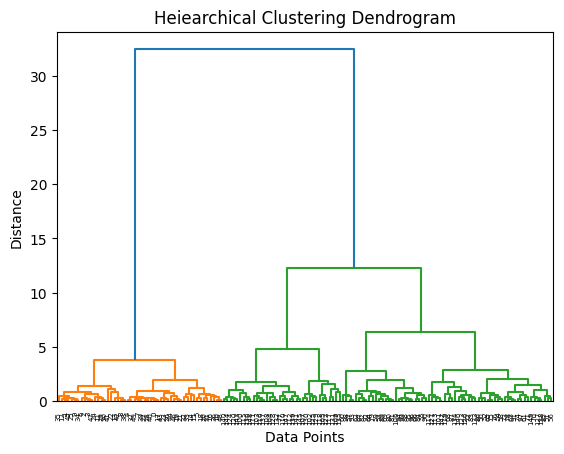

In [42]:
plt.Figure(figsize=(6,4))
dendrogram(linked)
plt.title('Heiearchical Clustering Dendrogram')
plt.xlabel('Data Points')
plt.ylabel('Distance')
plt.show()

In [ ]:
#FileLink=[https://chatgpt.com/share/6ab41d3f-5388-83ee-87d9-b8ebb4a65aa7]


https://chatgpt.com/share/6ab41d3f-5388-83ee-87d9-b8ebb4a65aa7

In [ ]:
Lecture 98 — Unsupervised Learning & Clustering
1. Unsupervised Learning kya hota hai?
Notebook starts with:
Unsupervised Learning:
Clustering

Simple meaning
Unsupervised Learning mein hum computer ko data dete hain, lekin usko pehle se answer nahi batate.
Example:
Suppose tumhare paas 100 students hain:
Student	Height	Weight
A	150	45
B	152	47
C	180	80
D	182	82


Hum computer ko nahi bolte ki:
"Ye Group 1 hai aur ye Group 2 hai."

Computer khud similar students ko groups mein divide karne ki koshish karta hai.
Ye groups banana = Clustering.
Easy example
Socho tumhare paas bahut saare fruits hain:
🍎 🍎 🍎 🍌 🍌 🍊 🍊
Aur tum computer ko bolte ho:
"In fruits ko unki similarity ke according groups mein divide karo."

Computer similar fruits ko ek group mein rakhne ki koshish karega.
2. Libraries Import Karna
Code:
import pandas as pdimport numpy as npimport matplotlib.pyplot as pltimport seaborn as sns


Chalo ek-ek line samajhte hain.
Line 1
import pandas as pd


Meaning:
Hum Pandas library ko import kar rahe hain.
Pandas ka use hota hai:
- Data read karne ke liye
- Data clean karne ke liye
- Data ko table form mein handle karne ke liye
Example:
Name    Age
Ram     20
Shyam   21

Pandas is table ko easily handle kar sakta hai.
as pd
Hum Pandas ka short name pd rakh rahe hain.
Instead of:
pandas.DataFrame()


we can write:
pd.DataFrame()


3. NumPy
import numpy as np


NumPy numerical calculations ke liye use hota hai.
For example:
np.array([10,20,30])


Numbers ke saath kaam karna easy ho jata hai.
np = NumPy ka short name.
4. Matplotlib
import matplotlib.pyplot as plt


Matplotlib ka use graphs/charts banane ke liye hota hai.
For example:
plt.plot()plt.show()


Graph screen par dikhane ke liye.
plt = matplotlib.pyplot ka short name.
5. Seaborn
import seaborn as sns


Seaborn bhi graphs banane ke liye use hota hai.
Ye Matplotlib ke upar based hai aur statistical graphs ko easily banane mein help karta hai.
Example:
sns.scatterplot()


 sns = Seaborn ka short name.
6. Iris Dataset Load Karna
df = sns.load_dataset('iris')


Ye bahut important line hai.
sns.load_dataset('iris')
Seaborn ke andar ek famous dataset hai:
Iris dataset
Isme flowers ka data hota hai.
Example columns:
sepal_length
sepal_width
petal_length
petal_width
species

Flowers ki different measurements di hui hain.
df =
Hum dataset ko df naam ke variable mein store kar rahe hain.
df ka common meaning hota hai:
DataFrame

So:
df = sns.load_dataset('iris')


ka simple meaning:
"Iris dataset ko load karo aur df mein store karo."

7. Dataset ka Size
df.shape


shape batata hai:
Dataset mein kitni rows aur kitne columns hain?

Output kuch aisa ho sakta hai:
(150, 5)

Meaning:
- 150 rows
- 5 columns
Easy example
Agar classroom mein:
- 30 students
- 5 subjects
to shape:
(30,5)

8. Missing Values Check Karna
df.isnull().sum().sum()


Is line ko pieces mein samjho.
Step 1
df.isnull()


Ye check karta hai:
Kahan-kahan data missing hai?

Missing value ko Python generally:
NaN

ke form mein represent karta hai.
Step 2
.sum()


Missing values count karta hai.
Step 3
.sum().sum()


Pehla sum() columns-wise count karega.
Second sum() sab counts ko add karega.
Example:
Column A → 2 missing
Column B → 3 missing
Column C → 0 missing

Total:
2 + 3 + 0 = 5

So:
df.isnull().sum().sum()


total missing values batata hai.
9. First 3 Rows Dekhna
df.head(3)


head() dataset ki starting rows dikhata hai.
Normally:
df.head()


first 5 rows deta hai.
But:
df.head(3)


first 3 rows dega.
Example:
Row 1
Row 2
Row 3

10. Species Column Remove Karna
X=df.drop(columns=['species'])


Ye clustering ke liye bahut important line hai.
Iris dataset mein:
sepal_length
sepal_width
petal_length
petal_width
species

species actual answer/label hai.
Example:
setosa
versicolor
virginica

Hum clustering kar rahe hain, isliye hum computer ko actual answer nahi dena chahte.
Isliye:
columns=['species']


se species remove kar dete hain.
Result
X mein sirf:
sepal_length
sepal_width
petal_length
petal_width

rah jayenge.
Simple analogy
Teacher tumhe students ko groups mein divide karne ko bolta hai.
Agar teacher pehle hi bata de:
"Ye 10 students Group A mein hain."

To tumne grouping khud nahi ki.
Isliye clustering mein actual label hata dete hain.
11. X ke First 2 Rows
X.head(2)


X ki first 2 rows display karega.
🟢 K-MEANS CLUSTERING
Ab notebook ka main topic start hota hai.
12. KMeans Import
from sklearn.cluster import KMeans


sklearn = Scikit-learn.
Ye Python ki famous Machine Learning library hai.
cluster ke andar se hum:
KMeans


import kar rahe hain.
KMeans ek clustering algorithm hai.
13. KMeans Object Banana
kmeans = KMeans(n_clusters=3,random_state=11)


Yahan hum KMeans ko configure kar rahe hain.
n_clusters=3
Iska meaning:
Computer ko 3 groups banane hain.

Iris dataset mein 3 types ke flowers hain:
Setosa
Versicolor
Virginica

Isliye yahan 3 clusters liye gaye hain.
Important
n_clusters=3 ka matlab:
"3 clusters banao."

random_state=11
KMeans ke process mein kuch randomness ho sakti hai.
random_state=11 ek fixed starting/random condition provide karta hai.
Isse code dobara run karne par generally same result reproduce karna easy hota hai.
Easy example
Socho tum 3 students ko randomly first leader choose kar rahe ho.
Agar randomness control nahi karoge to har baar starting selection change ho sakta hai.
random_state=11 ek fixed starting point jaisa hai.
11 ka koi special mathematical meaning nahi hai.
Tum 10, 20, 42 etc. bhi use kar sakte ho.
14. KMeans Apply Karna
X['cluster']=kmeans.fit_predict(X)


Ye line bahut important hai.
Isko 3 parts mein samjho.
Part 1
kmeans.fit(X)


fit() ka meaning:
Algorithm data ko study/learn karta hai.

KMeans data ko dekhega aur similar points ko groups mein arrange karne ki koshish karega.
Part 2
predict()


Predict karta hai ki kaunsa data point kis cluster mein belong karta hai.
fit_predict()
Dono ka combination:
fit_predict()


Matlab:
Data se pattern learn karo + har row ka cluster number batao.

Part 3
X['cluster'] =


Ek naya column create hoga:
cluster

Example:
petal_length	petal_width	cluster
1.4	0.2	1
1.5	0.2	1
4.5	1.5	2
5.5	2.0	0


Important
Cluster numbers:
0
1
2

ka matlab ye ranking nahi hai.
Cluster 2 ka matlab "better" nahi hai.
Ye sirf group IDs hain.
15. Cluster Data Dekhna
X.head(3)


Ab first 3 rows mein new cluster column bhi dikhega.
📊 16. KMeans Graph
Ab ye long code hai:
plt.Figure(figsize=(12,3))


Yahan figure ka size set karne ki koshish ki gayi hai.
figsize=(12,3) ka meaning:
- width = 12
- height = 3
Important correction
Normally yahan:
plt.figure(figsize=(12,3))


use karna better/correct hai.
Aapke notebook mein:
plt.Figure(...)


likha hai, jo plt.figure() ke intended usage se different hai.
17. First Graph Position
plt.subplot(1,3,1)


Iska meaning:
1 row
3 columns
1st graph

Imagine:
[ Graph 1 ][ Graph 2 ][ Graph 3 ]

Hum first graph par kaam kar rahe hain.
18. Scatter Plot
sns.scatterplot(    x='petal_length',    y='petal_width',    hue='cluster',    data=X)


Scatter plot dots ka graph hota hai.
X-axis
x='petal_length'


X-axis par petal length.
Y-axis
y='petal_width'


Y-axis par petal width.
Color
hue='cluster'


Different clusters ko different colors se show karega.
Data
data=X


Data X DataFrame se lena hai.
19. Second Graph
plt.subplot(1,3,2)


Ab:
1 row
3 columns
2nd graph

select kiya.
20. Title
plt.title("Orignal Data")


Graph ka title set karta hai.
Yahan spelling:
Orignal

hai.
Better spelling:
Original

So ideally:
plt.title("Original Data")


21. Original Species Graph
sns.scatterplot(    x='petal_length',    y='petal_width',    hue='species',    data=df)


Yahan actual dataset df use ho raha hai.
Aur:
hue='species'


means actual flower species ke according colors.
So hum compare kar sakte hain:
Actual groups vs KMeans groups.

22. Third Graph
plt.subplot(1,3,3)


Means:
1 row
3 columns
3rd graph

23. Title
plt.title("K-Means Clustring")


Graph ka title:
K-Means Clustering

Spelling ideally:
plt.title("K-Means Clustering")


24. KMeans Cluster Graph
sns.scatterplot(    x='petal_length',    y='petal_width',    hue='cluster',    data=X)


Again KMeans ke groups show ho rahe hain.
25. Graph Show
plt.show()


Graph ko screen par display karta hai.
Without:
plt.show()


kuch environments mein graph properly display nahi hoga.
26. KMeans Advantages
Notebook mein:
# K-Means is Simple,Fast,Works well with Large Dataset


Comment hai.
# ka matlab:
Ye comment hai. Python isko execute nahi karta.

Comment ka purpose explanation dena hai.
Notebook ke according KMeans:
- Simple hai
- Fast hai
- Large datasets ke saath kaam kar sakta hai
Lekin important limitation
KMeans mein hume generally pehle:
n_clusters


dena padta hai.
Example:
KMeans(n_clusters=3)


🔵 DBSCAN
Ab notebook DBSCAN par aa raha hai.
27. DBSCAN kya hai?
Notebook:
DBSCAN:
DBSCAN(Density-Based Spatial Clustring of Application with Noise)
Unlike K-Means,DBSCAN does not require you to specify the number of cluster

DBSCAN ka full form hai:
Density-Based Spatial Clustering of Applications with Noise
Simple language:
DBSCAN nearby/dense data points ko group karta hai.

Aur KMeans ki tarah hume pehle:
n_clusters=3


dene ki zarurat nahi hoti.
28. DBSCAN Import
from sklearn.cluster import DBSCAN


Scikit-learn ke cluster module se DBSCAN import kar rahe hain.
29. DBSCAN Object
dbscan = DBSCAN(eps=0.5,min_samples=10)


Yahan do important settings hain.
eps=0.5
eps ka meaning roughly:
Ek point ke around kitni distance tak neighbors consider karne hain.

Imagine ek student ke around ek circle bana diya.
       ●
    ●  🟢  ●
       ●

Circle ka size eps control karta hai.
eps=0.5 means neighborhood radius 0.5.
30. min_samples=10
Iska meaning:
Kisi point ke neighborhood mein minimum kitne points hone chahiye taaki area sufficiently dense maana ja sake.

Yahan:
min_samples=10


means approximately 10 points ka minimum requirement.
Very important
min_samples ka number of clusters se direct meaning nahi hai.
For example:
DBSCAN(eps=0.5, min_samples=10)


mein 10 ka matlab:
❌ 10 clusters nahi.
It means:
✅ minimum neighborhood points requirement.
31. DBSCAN Apply
X['db_cluster'] = dbscan.fit_predict(    X.drop(columns=['cluster']))


Let's break it.
X.drop(columns=['cluster'])
KMeans ka cluster column hata diya.
Kyun?
Because DBSCAN ko original features par apply karna hai, previous KMeans cluster labels ko feature nahi banana.
dbscan.fit_predict(...)
DBSCAN:
1. Data ko study karta hai
2. Groups identify karta hai
3. Har point ko cluster label deta hai
New column
X['db_cluster']


DBSCAN ka result store karega.
Example:
db_cluster
0
0
0
1
1
-1

-1 important hai
DBSCAN mein:
-1

generally means:
Noise / outlier point

Yaani point kisi proper dense group mein fit nahi hua.
32. First 4 Rows
X.head(4)


First 4 rows show karega.
Ab X mein roughly ye columns honge:
sepal_length
sepal_width
petal_length
petal_width
cluster
db_cluster

📊 33. DBSCAN Graph
plt.figure(figsize=(12,3))


Graph ka size set kar rahe hain.
Yahan figure() correctly use hua hai.
First DBSCAN graph
plt.subplot(1,2,1)


Meaning:
1 row
2 columns
1st graph

Layout:
[ Graph 1 ][ Graph 2 ]

34. Original Data Title
plt.title("Original Data")


Graph ka title.
35. Original Data Scatter Plot
sns.scatterplot(    x='petal_length',    y='petal_width',    hue='species',    data=df)


Actual species ke according graph bana raha hai.
36. Second Graph
plt.subplot(1,2,2)


2nd graph select karta hai.
37. DBSCAN Title
plt.title("DBSCAN Clustering")


Graph ka title set karta hai.
38. DBSCAN Scatter Plot
sns.scatterplot(    x='petal_length',    y='petal_width',    hue='db_cluster',    data=X)


Yahan:
hue='db_cluster'


DBSCAN ke groups ke according colors show karega.
39. Show Graph
plt.show()


Graph display karega.
40. Second DBSCAN Visualization
Next code:
plt.figure(figsize=(12,3))


Again graph figure create karta hai.
plt.subplot(1,2,1)


First graph.
plt.title("Original Data")


Title.
41. Sepal Graph
sns.scatterplot(    x='sepal_length',    y='sepal_width',    hue='species',    data=df)


Ab hum:
X-axis:
sepal_length

Y-axis:
sepal_width

use kar rahe hain.
Aur colors actual species ke according hain.
42. DBSCAN Sepal Graph
plt.subplot(1,2,2)


Second graph.
Then:
plt.title("DBSCAN Clustering")


Title.
Then:
sns.scatterplot(    x='sepal_length',    y='sepal_width',    hue='db_cluster',    data=X)


DBSCAN clusters ko sepal length aur width ke according visualize karta hai.
Finally:
plt.show()


Graph display.
🟣 HIERARCHICAL CLUSTERING
Ab third clustering technique.
43. Hierarchical Clustering
Notebook:
Hierarchical Clustering:
Hierarchicalo clustring creates a tree-loke structure of clusters

Spelling mistakes hain, but concept:
Hierarchical clustering clusters ka tree-like structure banata hai.

Easy example
Socho school mein:
School
│
├── Class 5
│   ├── Group A
│   └── Group B
│
└── Class 6
    ├── Group C
    └── Group D

Ye tree jaisa structure hai.
Hierarchical clustering bhi data groups ka hierarchy/tree banata hai.
44. AgglomerativeClustering Import
from sklearn.cluster import AgglomerativeClustering


Scikit-learn se:
AgglomerativeClustering

import kar rahe hain.
Ye hierarchical clustering ka ek method hai.
Agglomerative ka simple meaning
Start mein:
Har point apna separate group.

Phir:
Similar groups ko dheere-dheere merge karte jao.

Example:
A  B  C  D

Initially:
[A] [B] [C] [D]

Then:
[AB] [CD]

Then:
[ABCD]

45. Install SciPy
!pip install scipy


! ka use Jupyter Notebook mein system command run karne ke liye hota hai.
pip install scipy

Scipy library install karta hai.
SciPy kyun?
Hierarchical clustering ke dendrogram ke liye SciPy ke functions use ho rahe hain.
Important
Agar SciPy already installed hai, usually dobara install karne ki zarurat nahi hoti.
46. Dendrogram Import
from scipy.cluster.hierarchy import dendrogram, linkage


SciPy se do functions import:
linkage
Data points/groups ke relationships calculate karta hai.
dendrogram
Tree-like graph banata hai.
🌳 47. Linkage Create Karna
linked = linkage(    X.drop(columns=['cluster','db_cluster']),    method='ward')


Ye hierarchical clustering ka important step hai.
X.drop(columns=['cluster','db_cluster'])
Hum:
cluster
db_cluster

columns remove kar rahe hain.
Kyun?
Because ye pehle banaye gaye cluster labels hain.
Hume hierarchical clustering ko original features par apply karna hai.
Remaining features:
sepal_length
sepal_width
petal_length
petal_width

48. linkage()
linkage(...)


Ye decide karta hai ki different data points/groups ke beech relationship/distance kaise calculate karni hai.
49. method='ward'
method='ward'


Ward method clusters ko merge karte waqt within-cluster variation ko consider karta hai.
5th-class language:
Aise groups ko merge karne ki koshish karta hai jisse group ke andar ke points unnecessarily bahut spread na ho jayein.

Simple idea:
Similar points ko saath rakhna.

🌳 50. Dendrogram
Next:
plt.Figure(figsize=(6,4))


Again notebook mein capital Figure use hua hai.
Better:
plt.figure(figsize=(6,4))


51. Dendrogram Draw
dendrogram(linked)


Ye tree-like graph banata hai.
Example conceptually:
        ┌───────┐
    ┌───┤       ├───
    │   └───────┘
────┤
    │

Is graph ko Dendrogram kehte hain.
52. Title
plt.title('Heiearchical Clustering Dendrogram')


Graph ka title.
Spelling better:
plt.title('Hierarchical Clustering Dendrogram')


53. X-axis Label
plt.xlabel('Data Points')


X-axis ka naam:
Data Points

54. Y-axis Label
plt.ylabel('Distance')


Y-axis:
Distance

Distance ka simple meaning
Do data points/groups kitne different ya door hain.
Example:
A -------- B

A aur B close hain → small distance.
A ------------------------- C

A aur C far hain → large distance.
Dendrogram mein generally jis height par groups merge hote hain, woh distance/dissimilarity ko represent karti hai.
55. Display
plt.show()


Dendrogram ko screen par show karta hai.
🧠 COMPLETE CONCEPT IN ONE SIMPLE STORY
Suppose tumhare paas 150 flowers hain.
Computer ko tum flowers ke naam nahi batate.
Tum sirf measurements dete ho:
Sepal Length
Sepal Width
Petal Length
Petal Width

Then different algorithms try to make groups.
🟢 KMeans
Tum bolte ho:
"Mujhe 3 groups chahiye."

KMeans(n_clusters=3)


Computer 3 groups banata hai.
🔵 DBSCAN
Tum nahi bolte:
"3 groups banao."

Instead tum bolte ho:
"Jo points ek doosre ke sufficiently close/dense hain unko group karo."

DBSCAN(eps=0.5, min_samples=10)


Aur agar koi point kisi dense group mein fit nahi hota:
-1

mil sakta hai, jo noise/outlier indicate karta hai.
🟣 Hierarchical Clustering
Ye groups ko step-by-step merge karta hai:
A B C D E
↓
AB CD E
↓
AB CDE
↓
ABCDE

Aur is process ko tree ke form mein:
Dendrogram

mein show kar sakte hain.
⭐ KMeans vs DBSCAN vs Hierarchical
Feature	KMeans	DBSCAN	Hierarchical
Clustering type	Centroid-based	Density-based	Tree-based
Number of clusters beforehand?	Usually yes	No	Not necessarily
Noise detect kar sakta?	Normally no	Yes	Not its main purpose
Main parameter	n_clusters	eps, min_samples	linkage method
Output visualization	Clusters	Clusters + noise	Dendrogram
Basic idea	Center ke around groups	Dense areas	Groups ko merge/split karna


🎯 Most Important Interview Points
1. Unsupervised Learning
Unsupervised learning mein labeled output nahi hota. Algorithm data ke patterns ya groups khud identify karta hai.

2. Clustering
Similar data points ko groups mein divide karna clustering kehlata hai.

3. KMeans
KMeans data ko predefined number of clusters mein divide karta hai.

4. n_clusters
KMeans(n_clusters=3)


means:
3 clusters create karne hain.

5. random_state
Results ko reproducible banane mein help karta hai.

6. DBSCAN
DBSCAN density ke basis par clusters identify karta hai aur noise/outliers ko identify kar sakta hai.

7. eps
Neighborhood/radius ka size define karta hai.

8. min_samples
Dense neighborhood ke liye minimum points ki requirement define karta hai.

9. -1 in DBSCAN
Usually noise/outlier point ko represent karta hai.

10. Hierarchical Clustering
Data points/groups ko hierarchical tree structure mein organize karta hai.

11. Dendrogram
Hierarchical clustering ke merging process ko tree-like graph mein show karta hai.

12. ward
Clusters ko merge karte waqt within-cluster variation ko minimize karne ki approach use karta hai.

⚠️ Aapke notebook mein 2 small corrections
Correction 1
Aapne likha:
plt.Figure(figsize=(12,3))


Better:
plt.figure(figsize=(12,3))


Same issue last dendrogram graph mein bhi:
plt.Figure(figsize=(6,4))


Better:
plt.figure(figsize=(6,4))


Correction 2
Aapne likha:
plt.title("Orignal Data")


Correct spelling:
plt.title("Original Data")


And:
"K-Means Clustring"


should be:
"K-Means Clustering"


These are mainly spelling/usage corrections, not changes to the clustering concept.